# 02e Umbral mínimo de reseñas: tamaño de la muestra y calidad del modelo

**Documento relacionado:** [`docs/03-analisis-exploratorio.md`](../docs/03-analisis-exploratorio.md) · **Acuerdo:** A-003 · **Decisión:** [0002 Mínimo de reseñas](../docs/decisiones/0002-minimo-de-resenas.md)

**Base:** [02a Antigüedad vs reseñas](02a_antiguedad_resenas.ipynb) (configuración, cálculo de la antigüedad y sesgo de exposición) y la tabla de umbrales de [02_eda](02_eda.ipynb).

## Objetivo

Comparar los umbrales mínimos de reseñas **5, 30, 50 y 100** que propuso el equipo el 2026-11-22, y medir su impacto en:

1. **Tamaño y composición del dataset:** cuántos juegos quedan, de qué cohortes y con qué antigüedad.
2. **Calidad del modelo:** qué tan bien predicen la proporción de reseñas positivas (D-003) unos modelos base entrenados con cada umbral, usando solo variables disponibles antes del lanzamiento.

| Entradas | Salidas |
|---|---|
| `steam_games.csv(.gz)` (versión 2026-11-19) | `reports/figures/02e_umbral_tamano.png`, `reports/figures/02e_umbral_modelo.png`, `reports/metrics/02e_umbral_*.csv` |

> [!warning] Alcance
> Es un experimento para decidir el umbral, no el modelo final. La limpieza (A-006), las variables (A-004, A-007) y la partición de evaluación (decisión 0003) siguen abiertas, así que aquí se usan versiones provisionales y sencillas de cada una. Lo que importa es la **comparación entre umbrales** con todo lo demás fijo.

## Configuración

Igual que en 02a, más los parámetros del experimento.

In [1]:
from pathlib import Path
import os
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.ticker import FuncFormatter

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, roc_auc_score
from scipy.stats import spearmanr

# Rutas del repositorio (el notebook vive en notebooks/)
rootDir = Path('..').resolve()
figuresDir = rootDir / 'reports' / 'figures'
metricsDir = rootDir / 'reports' / 'metrics'
processedDir = rootDir / 'data' / 'processed'
interimDir = rootDir / 'data' / 'interim'
for outPath in (figuresDir, metricsDir, processedDir, interimDir):
    outPath.mkdir(parents=True, exist_ok=True)

# Datos: versión del 2026-11-19. Se busca primero la variable de entorno STEAM_GAMES_CSV,
# luego data/raw/ y por último la carpeta Proyecto Final/Datos (fuera del repositorio).
dataCandidates = [
    Path(os.environ['STEAM_GAMES_CSV']) if 'STEAM_GAMES_CSV' in os.environ else None,
    rootDir / 'data' / 'raw' / 'steam_games.csv.gz',
    rootDir / 'data' / 'raw' / 'steam_games.csv',
    rootDir.parents[1] / 'Datos' / 'steam_games.csv.gz',
]
dataPath = next((p for p in dataCandidates if p is not None and p.exists()), None)
if dataPath is None:
    raise FileNotFoundError('No se encontró steam_games.csv(.gz); colócalo en data/raw/ o define STEAM_GAMES_CSV')
print('Datos:', dataPath.name)

snapshotDate = pd.Timestamp('2026-11-19')   # fecha de corte de la versión del dataset

# Parámetros del experimento (A-003)
thresholdList = [5, 30, 50, 100]      # umbrales mínimos de reseñas a comparar
cohortRange = (2014, 2024)            # cohortes del universo de modelado (D-002 y 02_eda)
minMonthsInStore = 12                 # antigüedad mínima, igual que en 02_eda
benchmarkMin = 100                    # el conjunto de prueba común usa juegos con >= 100 reseñas
successCut = 0.80                     # «bien recibido»: >= 80 % positivas (umbral «Positive» de Steam)
seedList = [42, 7, 123, 2024, 31415]  # repeticiones de la partición aleatoria
testSize = 0.20
randomSeed = 42

# Fuente latina + respaldo CJK (macOS: Hiragino/PingFang; Linux: Noto CJK). Solo las instaladas.
installedFonts = {f.name for f in fm.fontManager.ttflist}
cjkFonts = [f for f in ('Hiragino Sans GB', 'PingFang SC', 'Arial Unicode MS', 'Noto Sans CJK SC', 'Noto Sans CJK JP')
            if f in installedFonts]
plt.rcParams['font.family'] = ['DejaVu Sans'] + cjkFonts
pd.set_option('display.width', 200)
thresholdColors = {5: '#ADB5BD', 30: '#74C0FC', 50: '#1C7ED6', 100: '#0B3D91'}

Datos: steam_games.csv


## Carga

Se lee con `keep_default_na=False, na_values=['']`, como indica el [diccionario de datos](../docs/02-diccionario-datos.md), y solo con las columnas que se usan.

In [2]:
useCols = ['app_id', 'name', 'release_date', 'price', 'price_status', 'positive', 'negative',
           'developers', 'publishers', 'genres', 'categories', 'supported_languages', 'full_audio_languages',
           'notes', 'achievements', 'mac', 'linux', 'screenshots', 'movies', 'website', 'support_url',
           'support_email', 'steam_store_available']
gamesDf = pd.read_csv(dataPath, low_memory=False, keep_default_na=False, na_values=[''], usecols=useCols)
print(f'{gamesDf.shape[0]:,} filas × {gamesDf.shape[1]} columnas leídas')

gamesDf['releaseDate'] = pd.to_datetime(gamesDf['release_date'], errors='coerce', format='mixed')
gamesDf['releaseYear'] = gamesDf['releaseDate'].dt.year
gamesDf['positive'] = pd.to_numeric(gamesDf['positive'], errors='coerce')
gamesDf['negative'] = pd.to_numeric(gamesDf['negative'], errors='coerce')
gamesDf['reviewCount'] = gamesDf['positive'] + gamesDf['negative']
gamesDf['positiveRatio'] = gamesDf['positive'] / gamesDf['reviewCount'].replace(0, np.nan)
gamesDf['ageYears'] = (snapshotDate - gamesDf['releaseDate']).dt.days / 365.25
gamesDf['price'] = pd.to_numeric(gamesDf['price'], errors='coerce')

150,199 filas × 23 columnas leídas


## Variables previas al lanzamiento (versión provisional)

Solo columnas con momento **Pre** o **Pre\*** del diccionario. Sin texto libre (D-007) y sin el nombre del desarrollador o del publisher (D-006, D-009): de ellos solo se usa su historial previo.

| Grupo | Variables |
|---|---|
| Precio | `logPrice`, `isFree`, `priceUnavailable` (Pre\*: precio al 2026-11-19) |
| Fecha | `releaseYear` (control de cohorte), `releaseMonth` |
| Plataformas | `mac`, `linux` (`windows` es casi constante) |
| Idiomas | `nLanguages`, `nFullAudio` |
| Tienda | `logAchievements`, `nScreenshots`, `nMovies` (Pre\*), `hasWebsite`, `hasSupportUrl`, `hasSupportEmail`, `hasMatureNotice` |
| Géneros | Indicadores de géneros oficiales en inglés, incluidas las etiquetas comerciales Indie, Early Access y Free To Play (D-005 las separa; aquí entran como indicadores) |
| Categorías | Indicadores de las 30 categorías más frecuentes, sin Steam Trading Cards (Post) |
| Desarrollador y publisher | `logDevPrior`, `logPubPrior`: juegos que lanzó antes, contados con todo el catálogo y solo con fechas anteriores (A-004, sin fuga); `selfPublished` |

No se usan el éxito previo del desarrollador ni otras variables que dependan de reseñas, para que la comparación no se contamine con el propio umbral.

In [3]:
def parseJsonList(rawValue):
    # Lista JSON de textos u objetos {"id", "description"}; devuelve lista de textos.
    if not isinstance(rawValue, str) or not rawValue.startswith('['):
        return []
    try:
        items = json.loads(rawValue)
    except json.JSONDecodeError:
        return []
    return [str(it.get('description', '')).strip() if isinstance(it, dict) else str(it).strip() for it in items]


def countLanguages(rawValue):
    # supported_languages viene como lista JSON o como texto HTML («English<strong>*</strong>, French<br>...»).
    if not isinstance(rawValue, str) or rawValue.strip() in ('', '[]'):
        return 0
    if rawValue.startswith('['):
        return len([x for x in parseJsonList(rawValue) if x])
    cleanText = re.sub(r'<br>.*$', '', rawValue, flags=re.S)
    cleanText = re.sub(r'<[^>]+>|\*', '', cleanText)
    return len([x for x in cleanText.split(',') if x.strip()])


def countJsonItems(rawValue):
    if not isinstance(rawValue, str) or not rawValue.startswith('['):
        return 0
    try:
        return len(json.loads(rawValue))
    except json.JSONDecodeError:
        return 0


def hasText(series):
    return series.fillna('').astype(str).str.strip().str.len().gt(3).astype(int)


genreLists = gamesDf['genres'].map(parseJsonList)
categoryLists = gamesDf['categories'].map(parseJsonList)
devLists = gamesDf['developers'].map(lambda v: [x.lower() for x in parseJsonList(v) if x])
pubLists = gamesDf['publishers'].map(lambda v: [x.lower() for x in parseJsonList(v) if x])

featDf = pd.DataFrame(index=gamesDf.index)
featDf['logPrice'] = np.log1p(gamesDf['price'].clip(upper=200)).fillna(0)
featDf['priceUnavailable'] = gamesDf['price'].isna().astype(int)
featDf['isFree'] = (gamesDf['price_status'] == 'free').astype(int)
featDf['releaseYear'] = gamesDf['releaseYear']
featDf['releaseMonth'] = gamesDf['releaseDate'].dt.month
featDf['mac'] = (gamesDf['mac'].astype(str) == 'True').astype(int)
featDf['linux'] = (gamesDf['linux'].astype(str) == 'True').astype(int)
featDf['nLanguages'] = gamesDf['supported_languages'].map(countLanguages)
featDf['nFullAudio'] = gamesDf['full_audio_languages'].map(countJsonItems)
featDf['logAchievements'] = np.log1p(pd.to_numeric(gamesDf['achievements'], errors='coerce').fillna(0).clip(upper=5000))
featDf['nScreenshots'] = gamesDf['screenshots'].map(countJsonItems)
featDf['nMovies'] = gamesDf['movies'].map(countJsonItems)
featDf['hasWebsite'] = hasText(gamesDf['website'])
featDf['hasSupportUrl'] = hasText(gamesDf['support_url'])
featDf['hasSupportEmail'] = hasText(gamesDf['support_email'])
featDf['hasMatureNotice'] = hasText(gamesDf['notes'])
featDf['selfPublished'] = [int(bool(set(d) & set(p))) for d, p in zip(devLists, pubLists)]

# Géneros oficiales en inglés (los traducidos aparecen 1 o 2 veces y se ignoran)
genreList = ['Indie', 'Casual', 'Action', 'Adventure', 'Simulation', 'Strategy', 'RPG', 'Free To Play',
             'Early Access', 'Sports', 'Racing', 'Massively Multiplayer', 'Violent', 'Gore', 'Nudity', 'Sexual Content']
for genreName in genreList:
    featDf['g_' + re.sub(r'\W+', '', genreName)] = genreLists.map(lambda gs: int(genreName in gs))

# Categorías más frecuentes, sin Steam Trading Cards (Steam la activa por ventas: fuga)
categoryCounts = categoryLists.explode().value_counts()
categoryCounts = categoryCounts[~categoryCounts.index.isin(['', 'Steam Trading Cards']) &
                                ~categoryCounts.index.astype(str).str.startswith('#')]
categoryList = categoryCounts.head(30).index.tolist()
for categoryName in categoryList:
    featDf['c_' + re.sub(r'\W+', '', categoryName)] = categoryLists.map(lambda cs: int(categoryName in cs))


def priorReleaseCount(entityLists):
    # Juegos del mismo desarrollador/publisher lanzados ANTES de cada juego (mismas fechas no cuentan).
    longDf = pd.DataFrame({'row': gamesDf.index, 'entity': entityLists, 'date': gamesDf['releaseDate']})
    longDf = longDf.explode('entity').dropna(subset=['entity', 'date']).sort_values(['entity', 'date'])
    longDf['prior'] = longDf.groupby('entity').cumcount()
    longDf['prior'] = longDf.groupby(['entity', 'date'])['prior'].transform('min')
    return longDf.groupby('row')['prior'].max().reindex(gamesDf.index).fillna(0)


featDf['logDevPrior'] = np.log1p(priorReleaseCount(devLists))
featDf['logPubPrior'] = np.log1p(priorReleaseCount(pubLists))
featureCols = list(featDf.columns)
print(f'{len(featureCols)} variables:', ', '.join(featureCols[:16]), '…')

65 variables: logPrice, priceUnavailable, isFree, releaseYear, releaseMonth, mac, linux, nLanguages, nFullAudio, logAchievements, nScreenshots, nMovies, hasWebsite, hasSupportUrl, hasSupportEmail, hasMatureNotice …


## Universo de modelado

Mismo universo que [02_eda](02_eda.ipynb): cohortes 2014–2024 (D-002) con al menos 12 meses en tienda. Además, como limpieza mínima provisional:

- se quita el precio atípico de 107,500 dólares (D-004) y las filas con `steam_store_available = False`;
- se quitan las aplicaciones cuyos géneros son solo de software (Utilities, Design & Illustration, …) o cuyo nombre indica que no son juegos (Soundtrack, Demo, Playtest, SDK, Dedicated Server), como pide D-005.

In [4]:
softwareGenres = {'Utilities', 'Design & Illustration', 'Animation & Modeling', 'Education', 'Video Production',
                  'Game Development', 'Audio Production', 'Software Training', 'Photo Editing', 'Web Publishing',
                  'Accounting', 'Movie', 'Documentary', 'Episodic', 'Short', 'Tutorial', '360 Video'}
onlySoftware = genreLists.map(lambda gs: len(gs) > 0 and set(gs) <= softwareGenres)
nonGameName = gamesDf['name'].fillna('').str.contains(r'\b(?:soundtrack|OST|demo|playtest|SDK|dedicated server)\b',
                                                      case=False, regex=True)

filterSteps = [
    ('Catálogo completo', pd.Series(True, index=gamesDf.index)),
    (f'Cohortes {cohortRange[0]}–{cohortRange[1]}', gamesDf['releaseYear'].between(*cohortRange)),
    (f'≥ {minMonthsInStore} meses en tienda', gamesDf['releaseDate'] <= snapshotDate - pd.DateOffset(months=minMonthsInStore)),
    ('Sin precio atípico (D-004) y con datos de tienda', (gamesDf['price'].fillna(0) < 1000)
                                                        & (gamesDf['steam_store_available'].astype(str) == 'True')),
    ('Solo juegos (D-005, provisional)', ~onlySoftware & ~nonGameName),
    ('Con conteo de reseñas', gamesDf['reviewCount'].notna()),
]
keepMask = pd.Series(True, index=gamesDf.index)
funnelRows = []
for stepName, stepMask in filterSteps:
    keepMask &= stepMask
    funnelRows.append({'paso': stepName, 'juegos': int(keepMask.sum())})
display(pd.DataFrame(funnelRows))

universeDf = pd.concat([gamesDf.loc[keepMask, ['app_id', 'name', 'releaseDate', 'releaseYear', 'ageYears',
                                               'reviewCount', 'positiveRatio']],
                        featDf.loc[keepMask].drop(columns='releaseYear')], axis=1).reset_index(drop=True)
universeDf['releaseYear'] = universeDf['releaseYear'].astype(int)
print(f'Universo: {len(universeDf):,} juegos')

,paso,juegos
0,Catálogo completo,150199
1,Cohortes 2014–2024,95293
2,≥ 12 meses en tienda,95293
3,Sin precio atípico (D-004) y con datos de tienda,95293
4,"Solo juegos (D-005, provisional)",89282
5,Con conteo de reseñas,89282


Universo: 89,282 juegos


## 1. Impacto en el tamaño y la composición del dataset

Para cada umbral se mide cuántos juegos quedan y **cuáles**. El notebook 02a mostró que el número de reseñas crece con la antigüedad (ρ ≈ 0.69), así que un umbral alto no solo reduce la muestra: la carga hacia juegos antiguos y más exitosos.

También se mide el **ruido de la etiqueta**. Con \(n\) reseñas, la proporción observada \(\hat p\) tiene una varianza de muestreo de aproximadamente \(\hat p(1-\hat p)/n\). La **confiabilidad** es la fracción de la varianza de la proporción que no es ruido:

$$\text{confiabilidad} = 1 - \frac{\overline{\hat p(1-\hat p)/n}}{\operatorname{Var}(\hat p)}$$

Es un techo aproximado del \(R^2\) que podría alcanzar cualquier modelo con esa etiqueta.

In [5]:
recentYears = [2022, 2023, 2024]
sizeRows = []
for minReviews in thresholdList:
    keptDf = universeDf[universeDf['reviewCount'] >= minReviews]
    ratio = keptDf['positiveRatio']
    noiseVar = (ratio * (1 - ratio) / keptDf['reviewCount']).mean()
    sizeRows.append({
        'minResenas': minReviews,
        'juegos': len(keptDf),
        'pctUniverso': len(keptDf) / len(universeDf) * 100,
        'pctVsUmbral5': np.nan,
        'medianaAntiguedad': keptDf['ageYears'].median(),
        'pctCohortes2022a2024': keptDf['releaseYear'].isin(recentYears).mean() * 100,
        'pctAutopublicados': keptDf['selfPublished'].mean() * 100,
        'pctGratis': keptDf['isFree'].mean() * 100,
        'mediaRatio': ratio.mean(),
        'medianaRatio': ratio.median(),
        'desvRatio': ratio.std(),
        'pctBienRecibidos': (ratio >= successCut).mean() * 100,
        'confiabilidad': 1 - noiseVar / ratio.var(),
    })
sizeDf = pd.DataFrame(sizeRows)
sizeDf['pctVsUmbral5'] = sizeDf['juegos'] / sizeDf.loc[0, 'juegos'] * 100
sizeDf.to_csv(metricsDir / '02e_umbral_tamano.csv', index=False)
sizeDf.round(3)

,minResenas,juegos,pctUniverso,pctVsUmbral5,medianaAntiguedad,pctCohortes2022a2024,pctAutopublicados,pctGratis,mediaRatio,medianaRatio,desvRatio,pctBienRecibidos,confiabilidad
0,5,60345,67.589,100.000,6.021,37.175,72.094,11.774,0.762,0.803,0.194,52.377,0.825
1,30,33603,37.637,55.685,6.716,31.518,66.655,12.948,0.776,0.812,0.162,53.046,0.939
2,50,26975,30.213,44.701,6.902,30.469,64.775,12.719,0.783,0.817,0.155,54.321,0.959
3,100,19769,22.142,32.760,7.012,29.637,62.128,12.590,0.794,0.826,0.147,57.074,0.977


### Retención por cohorte

Porcentaje de los juegos de cada cohorte que pasa cada umbral.

In [6]:
cohortRetention = pd.DataFrame({
    f'≥ {t}': universeDf.groupby('releaseYear')['reviewCount'].apply(lambda s, t=t: (s >= t).mean() * 100)
    for t in thresholdList
})
cohortRetention.insert(0, 'juegos', universeDf.groupby('releaseYear').size())
cohortRetention.to_csv(metricsDir / '02e_umbral_retencion_cohorte.csv')
cohortRetention.round(1)

,juegos,≥ 5,≥ 30,≥ 50,≥ 100
releaseYear,,,,,
2014,1492,99.5,95.8,91.0,77.7
2015,2463,99.1,86.5,76.6,60.7
2016,4034,96.9,73.4,62.8,47.7
2017,5760,89.3,57.3,46.2,33.0
2018,7325,83.6,47.6,36.6,25.6
2019,7088,77.4,42.0,33.7,24.5
2020,8623,75.8,40.1,31.5,22.9
2021,10260,66.2,31.9,24.7,17.9
2022,11248,59.7,28.0,21.5,15.4


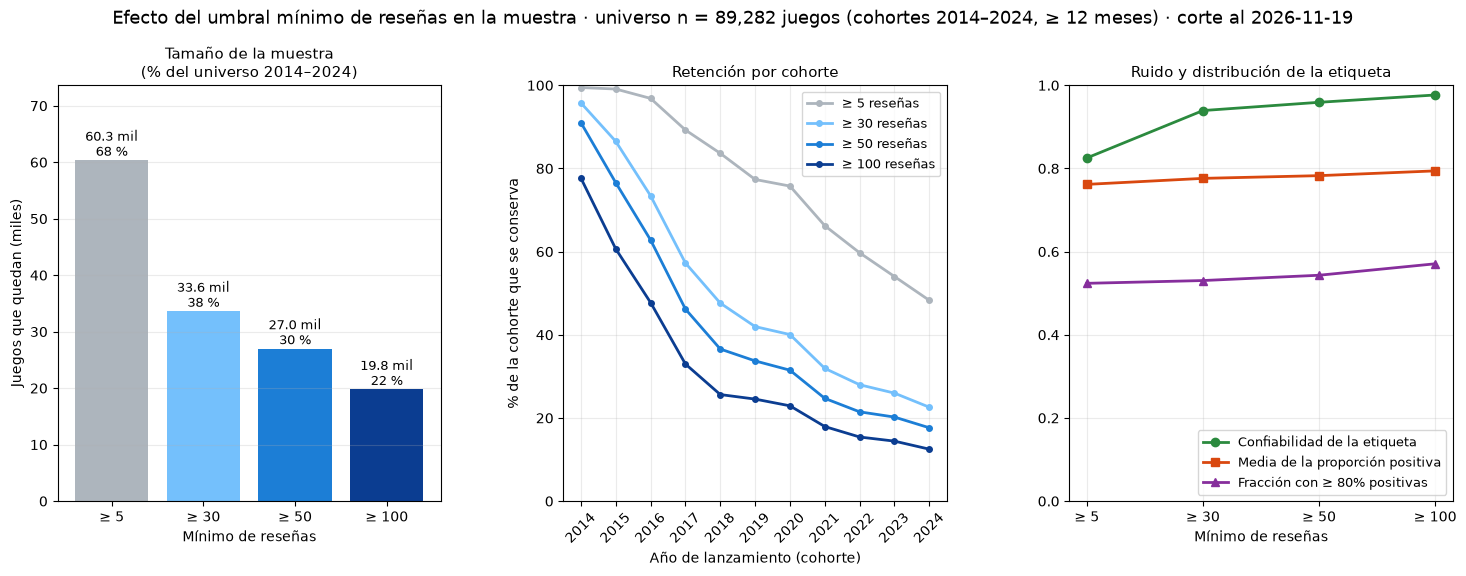

In [7]:
fig, (axSize, axCohort, axRel) = plt.subplots(1, 3, figsize=(18, 5.4), gridspec_kw={'wspace': 0.32})

xPos = np.arange(len(thresholdList))
axSize.bar(xPos, sizeDf['juegos'] / 1000, color=[thresholdColors[t] for t in thresholdList])
for x, (n, pct) in enumerate(zip(sizeDf['juegos'], sizeDf['pctUniverso'])):
    axSize.text(x, n / 1000 + 0.8, f'{n/1000:.1f} mil\n{pct:.0f} %', ha='center', fontsize=9)
axSize.set_xticks(xPos)
axSize.set_xticklabels([f'≥ {t}' for t in thresholdList])
axSize.set_xlabel('Mínimo de reseñas')
axSize.set_ylabel('Juegos que quedan (miles)')
axSize.set_ylim(0, sizeDf['juegos'].max() / 1000 * 1.22)
axSize.set_title('Tamaño de la muestra\n(% del universo 2014–2024)', fontsize=11)
axSize.grid(axis='y', alpha=0.25)

for t in thresholdList:
    axCohort.plot(cohortRetention.index, cohortRetention[f'≥ {t}'], marker='o', ms=4, lw=2,
                  color=thresholdColors[t], label=f'≥ {t} reseñas')
axCohort.set_xticks(cohortRetention.index)
axCohort.tick_params(axis='x', rotation=45)
axCohort.set_ylim(0, 100)
axCohort.set_xlabel('Año de lanzamiento (cohorte)')
axCohort.set_ylabel('% de la cohorte que se conserva')
axCohort.set_title('Retención por cohorte', fontsize=11)
axCohort.legend(fontsize=9)
axCohort.grid(alpha=0.25)

axRel.plot(xPos, sizeDf['confiabilidad'], color='#2B8A3E', marker='o', lw=2, label='Confiabilidad de la etiqueta')
axRel.plot(xPos, sizeDf['mediaRatio'], color='#D9480F', marker='s', lw=2, label='Media de la proporción positiva')
axRel.plot(xPos, sizeDf['pctBienRecibidos'] / 100, color='#862E9C', marker='^', lw=2,
           label=f'Fracción con ≥ {successCut:.0%} positivas')
axRel.set_xticks(xPos)
axRel.set_xticklabels([f'≥ {t}' for t in thresholdList])
axRel.set_ylim(0, 1)
axRel.set_xlabel('Mínimo de reseñas')
axRel.set_title('Ruido y distribución de la etiqueta', fontsize=11)
axRel.legend(fontsize=9, loc='lower right')
axRel.grid(alpha=0.25)

fig.suptitle(f'Efecto del umbral mínimo de reseñas en la muestra · universo n = {len(universeDf):,} juegos '
             f'(cohortes {cohortRange[0]}–{cohortRange[1]}, ≥ {minMonthsInStore} meses) · corte al {snapshotDate.date()}',
             fontsize=13, y=1.02)
fig.savefig(figuresDir / '02e_umbral_tamano.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Impacto en la calidad del modelo

### Diseño del experimento

Comparar el \(R^2\) de cada umbral **sobre su propio conjunto de prueba** es engañoso: con un umbral alto la prueba también tiene etiquetas menos ruidosas, y el modelo parece mejor aunque no lo sea. Por eso cada modelo se evalúa de tres formas:

| Evaluación | Conjunto de prueba | Qué responde |
|---|---|---|
| **Propia** | Juegos de prueba con ≥ umbral reseñas | Qué tan bien se ve el modelo con la muestra que define ese umbral |
| **Común** | Los mismos juegos de prueba para todos los umbrales: los que tienen ≥ 100 reseñas | Con cuál umbral de entrenamiento se predice mejor una etiqueta confiable |
| **Mismo tamaño** | Común, pero entrenando con una submuestra del tamaño del umbral 100 | Si la diferencia viene del tamaño de la muestra o de la calidad de la etiqueta |

La partición es aleatoria por juego (80/20) y se repite con 5 semillas; los juegos de prueba nunca se usan para entrenar en ningún umbral. Al final hay una comprobación con partición temporal (entrenar con 2014–2022 y probar con 2023–2024), porque la decisión 0003 sigue abierta.

### Modelos

- **Base por cohorte:** predice la media de la proporción positiva del año de lanzamiento en el entrenamiento.
- **Ridge:** regresión lineal regularizada con variables estandarizadas.
- **Gradient boosting** (`HistGradientBoostingRegressor`): capta no linealidades e interacciones.

### Métricas

\(R^2\), MAE y RMSE de la proporción positiva; correlación de Spearman entre predicción y valor real; y AUC para distinguir los juegos «bien recibidos» (≥ 80 % positivas) usando la predicción como puntaje.

In [8]:
def makeModels(seed):
    return {
        'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        'Gradient boosting': HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                                           min_samples_leaf=40, l2_regularization=1.0,
                                                           early_stopping=True, validation_fraction=0.1,
                                                           random_state=seed),
    }


def scorePredictions(yTrue, yPred):
    yPred = np.clip(yPred, 0, 1)
    isSuccess = (yTrue >= successCut).astype(int)
    return {
        'r2': r2_score(yTrue, yPred),
        'mae': mean_absolute_error(yTrue, yPred),
        'rmse': mean_squared_error(yTrue, yPred) ** 0.5,
        'spearman': spearmanr(yTrue, yPred).statistic if np.ptp(yPred) > 1e-9 else np.nan,
        'auc': roc_auc_score(isSuccess, yPred) if len(np.unique(isSuccess)) == 2 else np.nan,
    }


def evaluateThreshold(trainDf, evalSets, seed, label):
    # Entrena los modelos con trainDf y los evalúa en cada conjunto de evalSets.
    rows = []
    cohortMean = trainDf.groupby('releaseYear')['positiveRatio'].mean()
    latestMean = cohortMean.iloc[-1]   # cohortes sin datos de entrenamiento (partición temporal): la más reciente
    fittedModels = {name: model.fit(trainDf[featureCols], trainDf['positiveRatio'])
                    for name, model in makeModels(seed).items()}
    for evalName, evalDf in evalSets.items():
        predictions = {'Base por cohorte': evalDf['releaseYear'].map(cohortMean).fillna(latestMean).to_numpy()}
        predictions.update({name: model.predict(evalDf[featureCols]) for name, model in fittedModels.items()})
        for modelName, yPred in predictions.items():
            rows.append({'esquema': label, 'evaluacion': evalName, 'modelo': modelName, 'semilla': seed,
                         'nEntrenamiento': len(trainDf), 'nPrueba': len(evalDf),
                         **scorePredictions(evalDf['positiveRatio'].to_numpy(), yPred)})
    return rows

### Partición aleatoria repetida

In [9]:
poolDf = universeDf[universeDf['reviewCount'] >= min(thresholdList)].reset_index(drop=True)
sameSizeN = int((poolDf['reviewCount'] >= max(thresholdList)).sum() * (1 - testSize))
resultRows = []
for seed in seedList:
    trainIdx, testIdx = train_test_split(poolDf.index, test_size=testSize, random_state=seed)
    trainPool, testPool = poolDf.loc[trainIdx], poolDf.loc[testIdx]
    commonTest = testPool[testPool['reviewCount'] >= benchmarkMin]
    for minReviews in thresholdList:
        trainDf = trainPool[trainPool['reviewCount'] >= minReviews]
        ownTest = testPool[testPool['reviewCount'] >= minReviews]
        resultRows += evaluateThreshold(trainDf, {'Propia': ownTest, 'Común (≥ 100)': commonTest}, seed, minReviews)
        # Control de tamaño: misma cantidad de juegos de entrenamiento para todos los umbrales
        sameSizeDf = trainDf.sample(n=min(sameSizeN, len(trainDf)), random_state=seed)
        resultRows += evaluateThreshold(sameSizeDf, {'Común, mismo tamaño': commonTest}, seed, minReviews)
    print(f'Semilla {seed}: listo')

resultsDf = pd.DataFrame(resultRows).rename(columns={'esquema': 'minResenas'})
resultsDf.to_csv(metricsDir / '02e_umbral_modelo_detalle.csv', index=False)

metricCols = ['r2', 'mae', 'rmse', 'spearman', 'auc']
summaryDf = (resultsDf.groupby(['evaluacion', 'modelo', 'minResenas'])
             .agg(nEntrenamiento=('nEntrenamiento', 'mean'), nPrueba=('nPrueba', 'mean'),
                  **{m: (m, 'mean') for m in metricCols}, r2Desv=('r2', 'std'))
             .reset_index())
summaryDf.to_csv(metricsDir / '02e_umbral_modelo_resumen.csv', index=False)

Semilla 42: listo


Semilla 7: listo


Semilla 123: listo


Semilla 2024: listo


Semilla 31415: listo


### Resultados: gradient boosting

Media de las 5 semillas; `r2Desv` es la desviación estándar del \(R^2\) entre semillas.

In [10]:
evalOrder = ['Propia', 'Común (≥ 100)', 'Común, mismo tamaño']
gbTable = (summaryDf[summaryDf['modelo'] == 'Gradient boosting']
           .assign(evaluacion=lambda d: pd.Categorical(d['evaluacion'], evalOrder, ordered=True))
           .sort_values(['evaluacion', 'minResenas'])
           .drop(columns='modelo'))
gbTable.round(3)

,evaluacion,minResenas,nEntrenamiento,nPrueba,r2,mae,rmse,spearman,auc,r2Desv
28,Propia,5,48276.0,12069.0,0.231,0.132,0.171,0.484,0.738,0.005
29,Propia,30,26911.0,6692.0,0.272,0.107,0.138,0.512,0.746,0.008
30,Propia,50,21613.0,5362.0,0.261,0.103,0.133,0.502,0.742,0.011
31,Propia,100,15848.8,3920.2,0.256,0.097,0.126,0.501,0.743,0.015
4,Común (≥ 100),5,48276.0,3920.2,0.181,0.106,0.133,0.458,0.722,0.010
5,Común (≥ 100),30,26911.0,3920.2,0.243,0.101,0.128,0.493,0.738,0.014
6,Común (≥ 100),50,21613.0,3920.2,0.253,0.099,0.127,0.496,0.739,0.014
7,Común (≥ 100),100,15848.8,3920.2,0.256,0.097,0.126,0.501,0.743,0.015
16,"Común, mismo tamaño",5,15815.0,3920.2,0.148,0.109,0.135,0.425,0.705,0.017
17,"Común, mismo tamaño",30,15815.0,3920.2,0.232,0.102,0.129,0.484,0.732,0.011


### Comparación de modelos en el conjunto de prueba común

\(R^2\) medio en los juegos de prueba con ≥ 100 reseñas.

In [11]:
modelPivot = (summaryDf[summaryDf['evaluacion'] == 'Común (≥ 100)']
              .pivot(index='modelo', columns='minResenas', values='r2')
              .reindex(['Base por cohorte', 'Ridge', 'Gradient boosting']))
modelPivot.columns = [f'≥ {c}' for c in modelPivot.columns]
modelPivot.round(3)

,≥ 5,≥ 30,≥ 50,≥ 100
modelo,,,,
Base por cohorte,-0.055,0.019,0.036,0.047
Ridge,0.077,0.146,0.164,0.174
Gradient boosting,0.181,0.243,0.253,0.256


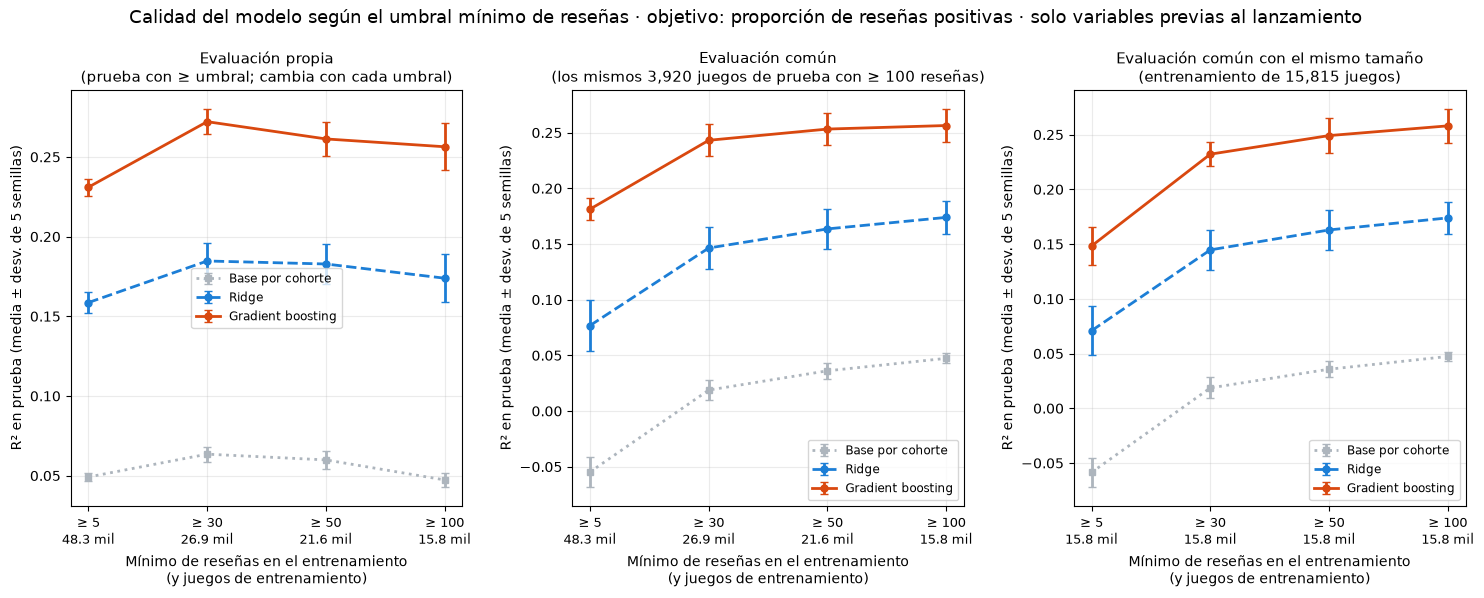

In [12]:
fig, axList = plt.subplots(1, 3, figsize=(18, 5.4), sharey=False, gridspec_kw={'wspace': 0.28})
modelStyles = {'Base por cohorte': ('#ADB5BD', 's', ':'), 'Ridge': ('#1C7ED6', 'o', '--'),
               'Gradient boosting': ('#D9480F', 'o', '-')}
for axCur, evalName in zip(axList, evalOrder):
    for modelName, (colorName, markerName, lineStyle) in modelStyles.items():
        subDf = summaryDf[(summaryDf['evaluacion'] == evalName) & (summaryDf['modelo'] == modelName)].sort_values('minResenas')
        axCur.errorbar(xPos, subDf['r2'], yerr=subDf['r2Desv'], color=colorName, marker=markerName, ls=lineStyle,
                       lw=2, ms=5, capsize=3, label=modelName)
    subN = summaryDf[(summaryDf['evaluacion'] == evalName) & (summaryDf['modelo'] == 'Ridge')].sort_values('minResenas')
    axCur.set_xticks(xPos)
    axCur.set_xticklabels([f'≥ {t}\n{n/1000:.1f} mil' for t, n in zip(thresholdList, subN['nEntrenamiento'])],
                          fontsize=9.5)
    axCur.set_xlabel('Mínimo de reseñas en el entrenamiento\n(y juegos de entrenamiento)')
    axCur.set_ylabel('R² en prueba (media ± desv. de 5 semillas)')
    nTest = int(subN['nPrueba'].mean())
    if evalName == 'Propia':
        subTitle = 'Evaluación propia\n(prueba con ≥ umbral; cambia con cada umbral)'
    elif evalName == 'Común (≥ 100)':
        subTitle = f'Evaluación común\n(los mismos {nTest:,} juegos de prueba con ≥ 100 reseñas)'
    else:
        subTitle = f'Evaluación común con el mismo tamaño\n(entrenamiento de {sameSizeN:,} juegos)'
    axCur.set_title(subTitle, fontsize=11)
    axCur.grid(alpha=0.25)
    axCur.legend(fontsize=8.5, loc='best')
fig.suptitle('Calidad del modelo según el umbral mínimo de reseñas · objetivo: proporción de reseñas positivas · '
             'solo variables previas al lanzamiento', fontsize=13, y=1.03)
fig.savefig(figuresDir / '02e_umbral_modelo.png', dpi=150, bbox_inches='tight')
plt.show()

### Comprobación con partición temporal

Se entrena con las cohortes 2014–2022 y se prueba con 2023–2024, que es como se usaría el modelo: predecir juegos nuevos con lo aprendido de los anteriores. La prueba común son los juegos de 2023–2024 con ≥ 100 reseñas.

In [13]:
temporalRows = []
trainPool = poolDf[poolDf['releaseYear'] <= 2022]
testPool = poolDf[poolDf['releaseYear'] >= 2023]
commonTest = testPool[testPool['reviewCount'] >= benchmarkMin]
for minReviews in thresholdList:
    trainDf = trainPool[trainPool['reviewCount'] >= minReviews]
    ownTest = testPool[testPool['reviewCount'] >= minReviews]
    temporalRows += evaluateThreshold(trainDf, {'Propia': ownTest, 'Común (≥ 100)': commonTest}, randomSeed, minReviews)
temporalDf = pd.DataFrame(temporalRows).rename(columns={'esquema': 'minResenas'})
temporalDf.to_csv(metricsDir / '02e_umbral_modelo_temporal.csv', index=False)
(temporalDf[temporalDf['modelo'] != 'Base por cohorte']
 .pivot_table(index=['evaluacion', 'modelo'], columns='minResenas', values=['r2', 'auc'])
 .round(3))

auc                          r2                     
minResenas                         5      30     50     100    5      30     50     100
evaluacion    modelo                                                                   
Común (≥ 100) Gradient boosting  0.694  0.714  0.726  0.724  0.080  0.160  0.194  0.193
              Ridge              0.643  0.657  0.662  0.671  0.041  0.070  0.072  0.080
Propia        Gradient boosting  0.698  0.706  0.718  0.724  0.120  0.159  0.182  0.193
              Ridge              0.649  0.657  0.658  0.671  0.081  0.077  0.068  0.080

### Variables más importantes (gradient boosting, umbral 30)

Importancia por permutación en la prueba común de la primera semilla; sirve para comprobar que el modelo aprende algo razonable, no para seleccionar variables.

In [14]:
from sklearn.inspection import permutation_importance

trainIdx, testIdx = train_test_split(poolDf.index, test_size=testSize, random_state=seedList[0])
trainDf = poolDf.loc[trainIdx].query('reviewCount >= 30')
commonTest = poolDf.loc[testIdx].query('reviewCount >= @benchmarkMin')
gbModel = makeModels(seedList[0])['Gradient boosting'].fit(trainDf[featureCols], trainDf['positiveRatio'])
permResult = permutation_importance(gbModel, commonTest[featureCols], commonTest['positiveRatio'],
                                    n_repeats=5, random_state=seedList[0], scoring='r2')
importanceDf = (pd.DataFrame({'variable': featureCols, 'caidaR2': permResult.importances_mean})
                .sort_values('caidaR2', ascending=False).head(15).reset_index(drop=True))
importanceDf.round(4)

,variable,caidaR2
0,releaseYear,0.1612
1,c_SteamCloud,0.0427
2,logPrice,0.0350
3,g_Action,0.0300
4,logAchievements,0.0278
5,isFree,0.0205
6,logPubPrior,0.0199
7,g_Simulation,0.0191
8,nLanguages,0.0180
9,g_Strategy,0.0151


## Resumen para la decisión 0002

In [15]:
gbCommon = summaryDf[(summaryDf['modelo'] == 'Gradient boosting')]
decisionDf = sizeDf[['minResenas', 'juegos', 'pctUniverso', 'pctCohortes2022a2024', 'confiabilidad']].copy()
for evalName, colName in [('Propia', 'r2Propia'), ('Común (≥ 100)', 'r2Comun'), ('Común, mismo tamaño', 'r2MismoTamano')]:
    decisionDf[colName] = decisionDf['minResenas'].map(gbCommon[gbCommon['evaluacion'] == evalName].set_index('minResenas')['r2'])
decisionDf['aucComun'] = decisionDf['minResenas'].map(
    gbCommon[gbCommon['evaluacion'] == 'Común (≥ 100)'].set_index('minResenas')['auc'])
temporalGb = temporalDf[(temporalDf['modelo'] == 'Gradient boosting') & (temporalDf['evaluacion'] == 'Común (≥ 100)')]
decisionDf['r2Temporal'] = decisionDf['minResenas'].map(temporalGb.set_index('minResenas')['r2'])
decisionDf.to_csv(metricsDir / '02e_umbral_decision.csv', index=False)
decisionDf.round(3)

,minResenas,juegos,pctUniverso,pctCohortes2022a2024,confiabilidad,r2Propia,r2Comun,r2MismoTamano,aucComun,r2Temporal
0,5,60345,67.589,37.175,0.825,0.231,0.181,0.148,0.722,0.080
1,30,33603,37.637,31.518,0.939,0.272,0.243,0.232,0.738,0.160
2,50,26975,30.213,30.469,0.959,0.261,0.253,0.249,0.739,0.194
3,100,19769,22.142,29.637,0.977,0.256,0.256,0.258,0.743,0.193


## Conclusiones del notebook

Cifras de la ejecución con la versión del 2026-11-19 (universo de 89,282 juegos). Si cambian los filtros o las variables, hay que volver a revisarlas.

**Tamaño y composición**

- El umbral recorta mucho la muestra: con ≥ 5 reseñas quedan 60,345 juegos (68 % del universo); con ≥ 30, 33,603 (38 %); con ≥ 50, 26,975 (30 %), y con ≥ 100, 19,769 (22 %).
- El recorte no es parejo. En la cohorte 2014 se conserva entre 78 % y 99.5 % de los juegos con cualquier umbral, pero en 2024 solo 48 % pasa el umbral de 5 y 13 % el de 100. Las cohortes 2022–2024 bajan de 37 % de la muestra (≥ 5) a 30 % (≥ 100). Es el sesgo de exposición de [02a](02a_antiguedad_resenas.ipynb).
- Subir el umbral también selecciona juegos mejor recibidos (de 52 % a 57 % con ≥ 80 % positivas) y con menos autopublicación (de 72 % a 62 %). Un umbral alto describe juegos que ya tuvieron cierto alcance.

**Calidad de la etiqueta**

- La confiabilidad de la proporción positiva sube de 0.83 (≥ 5) a 0.94 (≥ 30), 0.96 (≥ 50) y 0.98 (≥ 100). Casi toda la ganancia ocurre entre 5 y 30 reseñas.

**Calidad del modelo**

- Con gradient boosting y la prueba común (los mismos juegos con ≥ 100 reseñas), el \\(R^2\\) es 0.18 (≥ 5), 0.24 (≥ 30), 0.25 (≥ 50) y 0.26 (≥ 100). La diferencia entre 30, 50 y 100 está dentro de la variación entre semillas (± 0.015).
- Con el **mismo tamaño** de entrenamiento el patrón se repite (0.15, 0.23, 0.25, 0.26). Lo que mejora el modelo es una etiqueta menos ruidosa, no tener más o menos juegos. Entrenar con ≥ 5 reseñas añade 30 mil juegos, pero con etiquetas tan ruidosas que el modelo empeora.
- En la evaluación propia el mejor umbral parece ser 30 (\\(R^2\\) = 0.27), pero no es comparable: cada umbral se prueba con juegos distintos.
- Con la partición temporal (entrenar con 2014–2022 y probar con 2023–2024), el \\(R^2\\) en la prueba común es 0.08, 0.16, 0.19 y 0.19. Los umbrales de 50 y 100 empatan, y los dos superan claramente al de 30. Predecir cohortes futuras es más difícil que una partición aleatoria, sobre todo porque la proporción positiva sube con los años (02_eda).
- Gradient boosting supera siempre a Ridge (≈ +0.08 de \\(R^2\\)) y al modelo base por cohorte. El AUC para distinguir juegos con ≥ 80 % positivas va de 0.72 a 0.74. Con las variables previas al lanzamiento se explica alrededor de una cuarta parte de la variación de la recepción.
- La variable más importante es el año de lanzamiento (control de cohorte), seguida de Steam Cloud, el precio, el género Action, los logros, ser gratuito y el historial del publisher.

**Propuesta para la decisión 0002**

- **Umbral de 50 reseñas.** Da prácticamente la misma calidad que 100 en las tres evaluaciones (y en la temporal, la mejor), conserva 36 % más juegos que 100 (26,975 contra 19,769) y pierde menos cohortes recientes.
- **30 reseñas** es una alternativa razonable si se prioriza el tamaño de la muestra. La partición temporal le cuesta unas 0.03 de \\(R^2\\).
- **5 reseñas no conviene:** la etiqueta tiene demasiado ruido.
- Con cualquier umbral, el modelo debe controlar la cohorte (año o percentil dentro de la cohorte, [02b](02b_percentiles_cohorte.ipynb)), y las conclusiones se limitan a juegos que ya alcanzaron ese mínimo de reseñas.

**Pendientes**

- Repetir la comparación cuando estén la limpieza (A-006), las variables de desarrollador (A-004) y la partición definitiva (0003).
- Probar el límite inferior de Wilson o ponderar por número de reseñas como alternativa al umbral. D-008 lo descarta por ahora.
- Combinar el umbral con filtros de antigüedad (segunda parte de A-003): cambiar `minMonthsInStore` en la configuración.